Mounted at /content/drive
GPU unavailable. Using CPU.
HOMEWORK 8 - PROBLEM 1
Device: cpu
Hardware: CPU
Epochs: 300
Batch size: 128
Learning rate: 0.001
Optimizer: SGD
Momentum: 0.9
Dataset directory: /content/drive/MyDrive/CIFAR10
Output directory: /content/drive/MyDrive/ECGR5105_HW8

Dataset Information
Training samples: 45000
Validation samples: 5000
Testing samples: 10000
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

EXISTING TRAINING PROGRESS
Baseline CNN (1.a): No existing checkpoint.
Extended CNN (1.b): No existing checkpoint.

Training: Baseline CNN (1.a)
BaselineCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=2048, out_fea

,Model,Epochs,GPU,Training Time (s),Training Time (min),Training Time per Epoch (s),Training Loss,Evaluation Accuracy (%),Parameters,Model Size (MiB)
0,FCNN (HW7),43,Not verified,440.760000,7.34600,10.250233,1.003400,53.73,1707274,6.512733
1,Baseline CNN (1.a),300,CPU,13084.769415,218.07949,43.615898,0.439856,66.11,25578,0.097572
2,Extended CNN (1.b),300,CPU,16283.598604,271.39331,54.278662,0.095810,68.00,33834,0.129066



PROBLEM 1(a): CNN VS FCNN
Accuracy difference: +12.38 percentage points
Parameter reduction: 98.50%
Total training time ratio (CNN / FCNN): 29.69
FCNN average training time per epoch: 10.25s
CNN average training time per epoch: 43.62s

PROBLEM 1(b): EXTENDED CNN VS BASELINE CNN
Accuracy difference: +1.89 percentage points
Parameter change: +32.28%
Training time change: +24.45%
Baseline training hardware: CPU
Extended training hardware: CPU


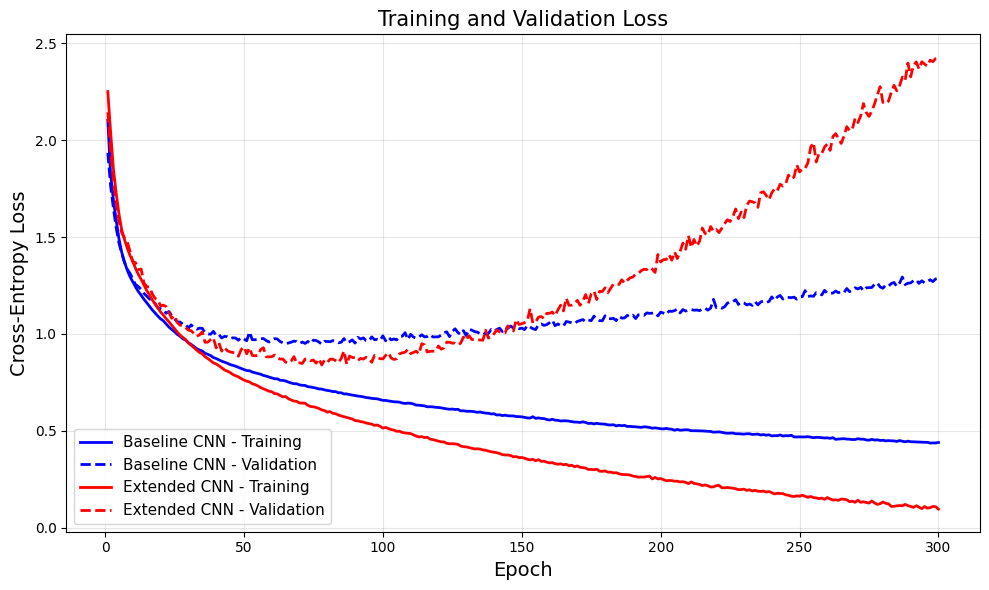

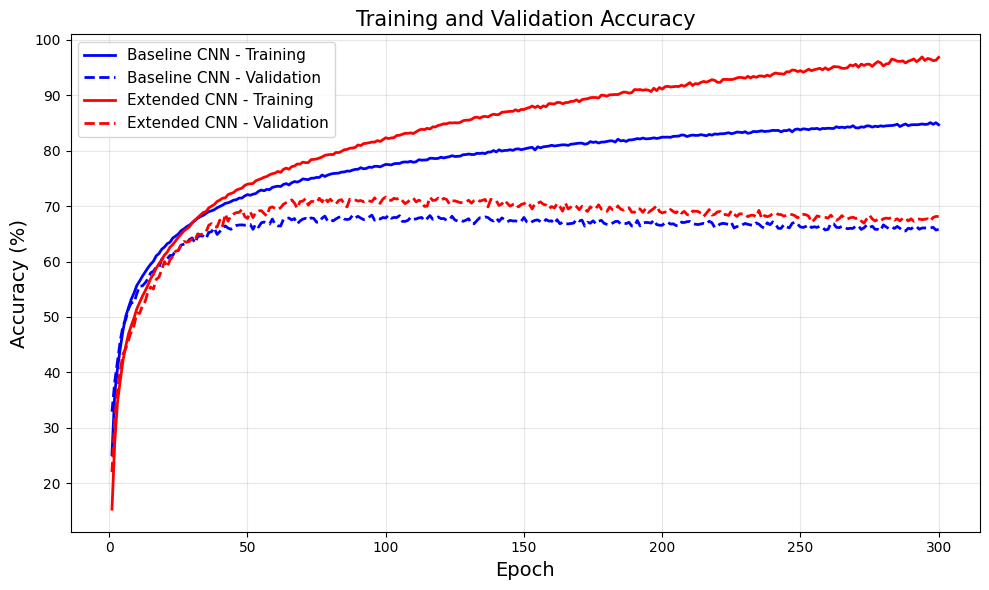


OVERFITTING ANALYSIS

Baseline CNN (1.a)
Final training accuracy: 84.69%
Final validation accuracy: 65.80%
Final evaluation accuracy: 66.11%
Training-validation accuracy gap: 18.89 percentage points
Minimum validation loss: 0.9470
Epoch with minimum validation loss: 78
Final validation loss: 1.2877
Increase from minimum validation loss: 0.3407

Extended CNN (1.b)
Final training accuracy: 96.86%
Final validation accuracy: 68.14%
Final evaluation accuracy: 68.00%
Training-validation accuracy gap: 28.72 percentage points
Minimum validation loss: 0.8399
Epoch with minimum validation loss: 78
Final validation loss: 2.4297
Increase from minimum validation loss: 1.5899


,Model,Final Training Accuracy (%),Final Validation Accuracy (%),Final Test Accuracy (%),Training-Validation Gap (pp),Minimum Validation Loss,Minimum Validation Loss Epoch,Final Validation Loss,Validation Loss Increase
0,Baseline CNN (1.a),84.6911,65.80,66.11,18.8911,0.9470,78,1.2877,0.3407
1,Extended CNN (1.b),96.8600,68.14,68.00,28.7200,0.8399,78,2.4297,1.5899



HOMEWORK 8 - PROBLEM 1 COMPLETED
All results saved to: /content/drive/MyDrive/ECGR5105_HW8


In [1]:
# ==============================================================
# ECGR 5105 - Introduction to Machine Learning
# Homework 8 - Problem 1(a) and Problem 1(b)
# Name: Irtiza Hasan
# Student ID: 801419720
#
# CIFAR-10 Classification Using CNN
# ==============================================================

import os
import gc
import time
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, random_split
from IPython.display import display


# ==============================================================
# 1. Configuration
# ==============================================================

SEED = 42
EPOCHS = 300
BATCH_SIZE = 128
LEARNING_RATE = 0.001
MOMENTUM = 0.9
NUM_WORKERS = 2

# Hardware options:
# "auto": GPU if available, otherwise CPU
# "gpu": Prefer GPU, fallback to CPU
# "cpu": CPU only

DEVICE_MODE = "auto"

RESUME_TRAINING = True

# Google Colab configuration.
# Set False when running outside Google Colab.

USE_GOOGLE_DRIVE = True

# Set True if CIFAR-10 has not been downloaded.

DOWNLOAD_DATASET = False

assert DEVICE_MODE in ["auto", "gpu", "cpu"]


# ==============================================================
# 2. Dataset and Output Directories
# ==============================================================

if USE_GOOGLE_DRIVE:

    from google.colab import drive

    if not os.path.isdir("/content/drive/MyDrive"):

        drive.mount(
            "/content/drive",
            timeout_ms=120000
        )

    DATA_DIR = "/content/drive/MyDrive/CIFAR10"

    OUTPUT_DIR = "/content/drive/MyDrive/ECGR5105_HW8"

else:

    DATA_DIR = "./data"

    OUTPUT_DIR = "./ECGR5105_HW8"

BASELINE_DIR = os.path.join(
    OUTPUT_DIR, "Problem_1a"
)

EXTENDED_DIR = os.path.join(
    OUTPUT_DIR, "Problem_1b"
)

os.makedirs(BASELINE_DIR, exist_ok=True)
os.makedirs(EXTENDED_DIR, exist_ok=True)


# ==============================================================
# 3. CPU/GPU Selection
# ==============================================================

def select_device():

    if DEVICE_MODE == "cpu":

        return torch.device("cpu")

    try:

        if torch.cuda.is_available():

            test_tensor = torch.zeros(
                1, device="cuda"
            )

            torch.cuda.synchronize()

            del test_tensor

            return torch.device("cuda")

    except (RuntimeError, AssertionError) as error:

        print("GPU initialization failed:", error)

    print("GPU unavailable. Using CPU.")

    return torch.device("cpu")


def hardware_name(device):

    if device.type == "cuda":

        return torch.cuda.get_device_name(
            device.index or 0
        )

    return "CPU"


def synchronize_device(device):

    if device.type == "cuda":

        torch.cuda.synchronize()


def set_seed(seed, device):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if device.type == "cuda":

        torch.cuda.manual_seed_all(seed)


device = select_device()

torch.set_num_threads(
    min(4, os.cpu_count() or 2)
)

if device.type == "cuda":

    torch.backends.cudnn.benchmark = True

set_seed(SEED, device)

print("=" * 70)
print("HOMEWORK 8 - PROBLEM 1")
print("=" * 70)

print("Device:", device)
print("Hardware:", hardware_name(device))
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Optimizer: SGD")
print("Momentum:", MOMENTUM)
print("Dataset directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)


# ==============================================================
# 4. Load CIFAR-10 Dataset
# ==============================================================

transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )

])

full_train_dataset = torchvision.datasets.CIFAR10(

    root=DATA_DIR,

    train=True,

    download=DOWNLOAD_DATASET,

    transform=transform

)

test_dataset = torchvision.datasets.CIFAR10(

    root=DATA_DIR,

    train=False,

    download=DOWNLOAD_DATASET,

    transform=transform

)

# Training: 45,000 images
# Validation: 5,000 images
# Testing: 10,000 images

train_dataset, val_dataset = random_split(

    full_train_dataset,

    [45000, 5000],

    generator=torch.Generator().manual_seed(SEED)

)

print("\nDataset Information")

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

print(
    "Number of classes:",
    len(full_train_dataset.classes)
)

print("Classes:", full_train_dataset.classes)


def create_loader(
    dataset,
    device,
    shuffle=False,
    generator=None
):

    return DataLoader(

        dataset,

        batch_size=BATCH_SIZE,

        shuffle=shuffle,

        generator=generator,

        num_workers=NUM_WORKERS,

        pin_memory=device.type == "cuda",

        persistent_workers=NUM_WORKERS > 0

    )


# ==============================================================
# 5. Problem 1(a): Baseline CNN
# ==============================================================

class BaselineCNN(nn.Module):

    def __init__(self):

        super(BaselineCNN, self).__init__()

        # Input: 3 x 32 x 32

        self.conv1 = nn.Conv2d(

            in_channels=3,

            out_channels=16,

            kernel_size=3,

            stride=1,

            padding=1

        )

        # After first pooling: 16 x 16 x 16

        self.conv2 = nn.Conv2d(

            in_channels=16,

            out_channels=32,

            kernel_size=3,

            stride=1,

            padding=1

        )

        # After second pooling: 32 x 8 x 8

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(

            kernel_size=2,

            stride=2

        )

        self.flatten = nn.Flatten()

        self.fc = nn.Linear(

            32 * 8 * 8,

            10

        )

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))

        x = self.pool(self.relu(self.conv2(x)))

        x = self.flatten(x)

        x = self.fc(x)

        return x


# ==============================================================
# 6. Problem 1(b): Extended CNN
# ==============================================================

class ExtendedCNN(nn.Module):

    def __init__(self):

        super(ExtendedCNN, self).__init__()

        # Input: 3 x 32 x 32

        self.conv1 = nn.Conv2d(

            in_channels=3,

            out_channels=16,

            kernel_size=3,

            stride=1,

            padding=1

        )

        # After first pooling: 16 x 16 x 16

        self.conv2 = nn.Conv2d(

            in_channels=16,

            out_channels=32,

            kernel_size=3,

            stride=1,

            padding=1

        )

        # After second pooling: 32 x 8 x 8

        self.conv3 = nn.Conv2d(

            in_channels=32,

            out_channels=64,

            kernel_size=3,

            stride=1,

            padding=1

        )

        # After third pooling: 64 x 4 x 4

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(

            kernel_size=2,

            stride=2

        )

        self.flatten = nn.Flatten()

        self.fc = nn.Linear(

            64 * 4 * 4,

            10

        )

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))

        x = self.pool(self.relu(self.conv2(x)))

        x = self.pool(self.relu(self.conv3(x)))

        x = self.flatten(x)

        x = self.fc(x)

        return x


# ==============================================================
# 7. Model Size Calculation
# ==============================================================

def count_parameters(model):

    return sum(

        p.numel()

        for p in model.parameters()

        if p.requires_grad

    )


def model_size_mib(model):

    total_bytes = sum(

        p.numel() * p.element_size()

        for p in model.parameters()

    )

    return total_bytes / (1024 ** 2)


# Verify model architectures.

assert count_parameters(BaselineCNN()) == 25578

assert count_parameters(ExtendedCNN()) == 33834


# ==============================================================
# 8. Evaluation Function
# ==============================================================

def evaluate(model, data_loader, criterion, device):

    model.eval()

    total_loss = 0.0

    correct = 0

    total = 0

    with torch.inference_mode():

        for images, labels in data_loader:

            images = images.to(

                device,

                non_blocking=device.type == "cuda"

            )

            labels = labels.to(

                device,

                non_blocking=device.type == "cuda"

            )

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (

                predictions == labels

            ).sum().item()

            total += labels.size(0)

    average_loss = total_loss / total

    accuracy = 100.0 * correct / total

    return average_loss, accuracy


# ==============================================================
# 9. Checkpoint and JSON Saving Functions
# ==============================================================

def save_json(data, path):

    temporary_path = path + ".tmp"

    with open(temporary_path, "w") as file:

        json.dump(data, file, indent=4)

    os.replace(temporary_path, path)


def save_checkpoint(checkpoint, path):

    temporary_path = path + ".tmp"

    torch.save(checkpoint, temporary_path)

    os.replace(temporary_path, path)


def save_history(history, save_dir):

    history_df = pd.DataFrame(history)

    history_df.insert(

        0,

        "Epoch",

        np.arange(1, len(history_df) + 1)

    )

    history_df.to_csv(

        os.path.join(

            save_dir,

            "training_history.csv"

        ),

        index=False

    )


# ==============================================================
# 10. Training Function
# ==============================================================

def train_model(
    model_class,
    model_name,
    save_dir,
    device
):

    set_seed(SEED, device)

    model = model_class().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(

        model.parameters(),

        lr=LEARNING_RATE,

        momentum=MOMENTUM

    )

    train_generator = torch.Generator().manual_seed(SEED)

    train_loader = create_loader(

        train_dataset,

        device,

        shuffle=True,

        generator=train_generator

    )

    val_loader = create_loader(

        val_dataset,

        device,

        shuffle=False

    )

    test_loader = create_loader(

        test_dataset,

        device,

        shuffle=False

    )

    checkpoint_path = os.path.join(

        save_dir, "checkpoint.pth"

    )

    results_path = os.path.join(

        save_dir, "final_results.json"

    )

    final_model_path = os.path.join(

        save_dir, "final_model.pth"

    )

    history = {

        "train_loss": [],

        "train_accuracy": [],

        "val_loss": [],

        "val_accuracy": [],

        "epoch_time": []

    }

    start_epoch = 0

    total_training_time = 0.0

    gpu_history = []

    # Keep this configuration compatible with
    # the existing Problem 1 checkpoints.

    configuration = {

        "model_name": model_name,

        "epochs": EPOCHS,

        "batch_size": BATCH_SIZE,

        "learning_rate": LEARNING_RATE,

        "momentum": MOMENTUM,

        "seed": SEED

    }

    # ----------------------------------------------------------
    # Resume existing checkpoint
    # ----------------------------------------------------------

    if RESUME_TRAINING and os.path.exists(checkpoint_path):

        # Only load trusted checkpoints generated
        # by this training code.

        checkpoint = torch.load(

            checkpoint_path,

            map_location="cpu",

            weights_only=False

        )

        if checkpoint["configuration"] != configuration:

            raise ValueError(

                "Checkpoint configuration mismatch. "
                "Check the saved settings before training."

            )

        model.load_state_dict(

            checkpoint["model_state_dict"]

        )

        optimizer.load_state_dict(

            checkpoint["optimizer_state_dict"]

        )

        # Move optimizer states to the selected device.

        for state in optimizer.state.values():

            for key, value in state.items():

                if torch.is_tensor(value):

                    state[key] = value.to(device)

        start_epoch = checkpoint["epoch"] + 1

        history = checkpoint["history"]

        total_training_time = checkpoint[

            "total_training_time"

        ]

        gpu_history = checkpoint.get(

            "gpu_history", []

        )

        # Restore random generator states.

        train_generator.set_state(

            checkpoint["train_generator_state"]

        )

        torch.set_rng_state(

            checkpoint["torch_rng_state"]

        )

        random.setstate(

            checkpoint["python_rng_state"]

        )

        np.random.set_state(

            checkpoint["numpy_rng_state"]

        )

        if (

            device.type == "cuda"

            and checkpoint.get("cuda_rng_state") is not None

            and len(checkpoint["cuda_rng_state"])

            == torch.cuda.device_count()

        ):

            torch.cuda.set_rng_state_all(

                checkpoint["cuda_rng_state"]

            )

        del checkpoint

        print("\nCheckpoint loaded:", model_name)

        print("Completed epochs:", start_epoch)

        print("Remaining epochs:", EPOCHS - start_epoch)

        print(

            "Previous training time:",

            f"{total_training_time / 60:.2f} minutes"

        )

        print("Previous hardware:", ", ".join(gpu_history))

        # Reuse existing results when training is complete.

        if (

            start_epoch == EPOCHS

            and os.path.exists(results_path)

        ):

            with open(results_path, "r") as file:

                results = json.load(file)

            if (

                results.get("Epochs") != EPOCHS

                or results.get("Model") != model_name

            ):

                raise ValueError(

                    "Saved final results do not match "
                    "the expected experiment."

                )

            save_history(history, save_dir)

            print(model_name, "already completed.")

            print("Using saved final results.")

            return model, history, results

    elif (

        os.path.exists(results_path)

        or os.path.exists(final_model_path)

        or os.path.exists(checkpoint_path)

    ):

        raise RuntimeError(

            "Existing experiment files detected. "
            "Enable checkpoint resumption or use a "
            "different output directory."

        )

    current_hardware = hardware_name(device)

    if start_epoch < EPOCHS:

        if current_hardware not in gpu_history:

            gpu_history.append(current_hardware)

    parameters = count_parameters(model)

    size_mib = model_size_mib(model)

    print("\n" + "=" * 70)
    print("Training:", model_name)
    print("=" * 70)

    print(model)

    print(f"Trainable parameters: {parameters:,}")

    print(f"Model size: {size_mib:.6f} MiB")

    print("Hardware:", current_hardware)

    print(

        f"Training epochs {start_epoch + 1} to {EPOCHS}"

    ) if start_epoch < EPOCHS else None

    # ----------------------------------------------------------
    # Train for exactly 300 epochs
    # ----------------------------------------------------------

    for epoch in range(start_epoch, EPOCHS):

        model.train()

        running_loss = 0.0

        correct = 0

        total = 0

        synchronize_device(device)

        epoch_start = time.perf_counter()

        for images, labels in train_loader:

            images = images.to(

                device,

                non_blocking=device.type == "cuda"

            )

            labels = labels.to(

                device,

                non_blocking=device.type == "cuda"

            )

            # Clear previous gradients.

            optimizer.zero_grad(set_to_none=True)

            # Forward propagation.

            outputs = model(images)

            loss = criterion(outputs, labels)

            # Backpropagation.

            loss.backward()

            # Update model parameters.

            optimizer.step()

            # Training statistics.

            running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (

                predictions == labels

            ).sum().item()

            total += labels.size(0)

        synchronize_device(device)

        epoch_time = time.perf_counter() - epoch_start

        total_training_time += epoch_time

        train_loss = running_loss / total

        train_accuracy = 100.0 * correct / total

        # Validation performance.

        val_loss, val_accuracy = evaluate(

            model,

            val_loader,

            criterion,

            device

        )

        history["train_loss"].append(train_loss)

        history["train_accuracy"].append(train_accuracy)

        history["val_loss"].append(val_loss)

        history["val_accuracy"].append(val_accuracy)

        history["epoch_time"].append(epoch_time)

        # ------------------------------------------------------
        # Save checkpoint after every completed epoch
        # ------------------------------------------------------

        checkpoint = {

            "epoch": epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "history":
                history,

            "total_training_time":
                total_training_time,

            "configuration":
                configuration,

            "gpu_history":
                gpu_history,

            "train_generator_state":
                train_generator.get_state(),

            "torch_rng_state":
                torch.get_rng_state(),

            "python_rng_state":
                random.getstate(),

            "numpy_rng_state":
                np.random.get_state(),

            "cuda_rng_state": (

                torch.cuda.get_rng_state_all()

                if device.type == "cuda"

                else None

            )

        }

        save_checkpoint(

            checkpoint,

            checkpoint_path

        )

        save_history(history, save_dir)

        del checkpoint

        remaining_epochs = EPOCHS - (epoch + 1)

        remaining_minutes = (

            remaining_epochs * epoch_time / 60

        )

        print(

            f"Epoch [{epoch + 1:3d}/{EPOCHS}] | "

            f"Train Loss: {train_loss:.4f} | "

            f"Train Acc: {train_accuracy:.2f}% | "

            f"Val Loss: {val_loss:.4f} | "

            f"Val Acc: {val_accuracy:.2f}% | "

            f"Time: {epoch_time:.2f}s | "

            f"Remaining: {remaining_minutes:.1f}min | "

            f"Device: {current_hardware}",

            flush=True

        )

    # ----------------------------------------------------------
    # Evaluate final model after 300 epochs
    # ----------------------------------------------------------

    test_loss, test_accuracy = evaluate(

        model,

        test_loader,

        criterion,

        device

    )

    results = {

        "Model":
            model_name,

        "Epochs":
            EPOCHS,

        "GPU":
            ", ".join(gpu_history),

        "Evaluation Device":
            current_hardware,

        "Training Time (s)":
            total_training_time,

        "Training Time (min)":
            total_training_time / 60,

        "Training Time per Epoch (s)":
            total_training_time / EPOCHS,

        "Training Loss":
            history["train_loss"][-1],

        "Training Accuracy (%)":
            history["train_accuracy"][-1],

        "Validation Loss":
            history["val_loss"][-1],

        "Validation Accuracy (%)":
            history["val_accuracy"][-1],

        "Test Loss":
            test_loss,

        "Evaluation Accuracy (%)":
            test_accuracy,

        "Parameters":
            parameters,

        "Model Size (MiB)":
            size_mib

    }

    # Save final model in a device-independent format.

    cpu_state_dict = {

        key: value.detach().cpu()

        for key, value in model.state_dict().items()

    }

    torch.save(

        cpu_state_dict,

        final_model_path

    )

    save_json(results, results_path)

    save_history(history, save_dir)

    print("\nFinal Results:", model_name)

    print("-" * 60)

    for key, value in results.items():

        if isinstance(value, float):

            print(f"{key}: {value:.6f}")

        else:

            print(f"{key}: {value}")

    return model, history, results


# ==============================================================
# 11. Automatic GPU-to-CPU Fallback
# ==============================================================

def is_cuda_error(error):

    message = str(error).lower()

    if "device-side assert" in message:

        return False

    keywords = [

        "cuda",

        "cudnn",

        "cublas",

        "out of memory",

        "driver shutting down",

        "device unavailable",

        "device is busy"

    ]

    return any(

        keyword in message

        for keyword in keywords

    )


def train_with_fallback(
    model_class,
    model_name,
    save_dir,
    device
):

    try:

        output = train_model(

            model_class,

            model_name,

            save_dir,

            device

        )

        return output, device

    except RuntimeError as error:

        if (

            device.type != "cuda"

            or not is_cuda_error(error)

        ):

            raise

        print("\nGPU training failed:", error)

        print(

            "Switching to CPU and resuming "
            "from the last saved checkpoint."

        )

    gc.collect()

    try:

        torch.cuda.empty_cache()

    except RuntimeError:

        pass

    device = torch.device("cpu")

    output = train_model(

        model_class,

        model_name,

        save_dir,

        device

    )

    return output, device


# ==============================================================
# 12. Check Existing Training Progress
# ==============================================================

print("\n" + "=" * 70)
print("EXISTING TRAINING PROGRESS")
print("=" * 70)

for name, folder in [

    ("Baseline CNN (1.a)", BASELINE_DIR),

    ("Extended CNN (1.b)", EXTENDED_DIR)

]:

    path = os.path.join(

        folder, "checkpoint.pth"

    )

    if os.path.exists(path):

        checkpoint = torch.load(

            path,

            map_location="cpu",

            weights_only=False

        )

        completed = checkpoint["epoch"] + 1

        print(

            f"{name}: "

            f"{completed}/{EPOCHS} epochs completed"

        )

        del checkpoint

    else:

        print(f"{name}: No existing checkpoint.")


# ==============================================================
# 13. Problem 1(a): Baseline CNN
# ==============================================================

baseline_output, device = train_with_fallback(

    BaselineCNN,

    "Baseline CNN (1.a)",

    BASELINE_DIR,

    device

)

baseline_model, baseline_history, baseline_results = (

    baseline_output

)

del baseline_output

baseline_model = baseline_model.cpu()

gc.collect()


# ==============================================================
# 14. Problem 1(b): Extended CNN
# ==============================================================

extended_output, device = train_with_fallback(

    ExtendedCNN,

    "Extended CNN (1.b)",

    EXTENDED_DIR,

    device

)

extended_model, extended_history, extended_results = (

    extended_output

)

del extended_output

extended_model = extended_model.cpu()

gc.collect()


# ==============================================================
# 15. Homework 7 FCNN Results
# ==============================================================

# Verify these values against the original HW7 submission.

hw7_results = {

    "Model":
        "FCNN (HW7)",

    "Epochs":
        43,

    "GPU":
        "Not verified",

    "Training Time (s)":
        440.76,

    "Training Time (min)":
        440.76 / 60,

    "Training Time per Epoch (s)":
        440.76 / 43,

    "Training Loss":
        1.0034,

    "Evaluation Accuracy (%)":
        53.73,

    "Parameters":
        1707274,

    "Model Size (MiB)":
        1707274 * 4 / (1024 ** 2)

}


# ==============================================================
# 16. Overall Model Comparison
# ==============================================================

comparison = pd.DataFrame([

    hw7_results,

    baseline_results,

    extended_results

])

comparison_columns = [

    "Model",

    "Epochs",

    "GPU",

    "Training Time (s)",

    "Training Time (min)",

    "Training Time per Epoch (s)",

    "Training Loss",

    "Evaluation Accuracy (%)",

    "Parameters",

    "Model Size (MiB)"

]

comparison = comparison[comparison_columns]

print("\n" + "=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

display(comparison.round(6))

comparison.to_csv(

    os.path.join(

        OUTPUT_DIR,

        "Problem_1_Model_Comparison.csv"

    ),

    index=False

)


# ==============================================================
# 17. Problem 1(a): CNN vs Homework 7 FCNN
# ==============================================================

accuracy_difference_1a = (

    baseline_results["Evaluation Accuracy (%)"]

    - hw7_results["Evaluation Accuracy (%)"]

)

parameter_reduction_1a = 100 * (

    hw7_results["Parameters"]

    - baseline_results["Parameters"]

) / hw7_results["Parameters"]

training_time_ratio_1a = (

    baseline_results["Training Time (s)"]

    / hw7_results["Training Time (s)"]

)

print("\nPROBLEM 1(a): CNN VS FCNN")

print(

    f"Accuracy difference: "

    f"{accuracy_difference_1a:+.2f} percentage points"

)

print(

    f"Parameter reduction: "

    f"{parameter_reduction_1a:.2f}%"

)

print(

    f"Total training time ratio (CNN / FCNN): "

    f"{training_time_ratio_1a:.2f}"

)

print(

    f"FCNN average training time per epoch: "

    f"{hw7_results['Training Time per Epoch (s)']:.2f}s"

)

print(

    f"CNN average training time per epoch: "

    f"{baseline_results['Training Time per Epoch (s)']:.2f}s"

)


# ==============================================================
# 18. Problem 1(b): Extended CNN vs Baseline CNN
# ==============================================================

accuracy_difference_1b = (

    extended_results["Evaluation Accuracy (%)"]

    - baseline_results["Evaluation Accuracy (%)"]

)

parameter_change_1b = 100 * (

    extended_results["Parameters"]

    - baseline_results["Parameters"]

) / baseline_results["Parameters"]

training_time_change_1b = 100 * (

    extended_results["Training Time (s)"]

    - baseline_results["Training Time (s)"]

) / baseline_results["Training Time (s)"]

print("\nPROBLEM 1(b): EXTENDED CNN VS BASELINE CNN")

print(

    f"Accuracy difference: "

    f"{accuracy_difference_1b:+.2f} percentage points"

)

print(

    f"Parameter change: "

    f"{parameter_change_1b:+.2f}%"

)

print(

    f"Training time change: "

    f"{training_time_change_1b:+.2f}%"

)

print(

    "Baseline training hardware:",

    baseline_results["GPU"]

)

print(

    "Extended training hardware:",

    extended_results["GPU"]

)

if baseline_results["GPU"] != extended_results["GPU"]:

    print(

        "\nNOTE: Training hardware differs. "
        "Training time differences cannot be "
        "attributed solely to model architecture."

    )


# ==============================================================
# 19. Training and Validation Loss
# ==============================================================

baseline_epochs = np.arange(

    1,

    len(baseline_history["train_loss"]) + 1

)

extended_epochs = np.arange(

    1,

    len(extended_history["train_loss"]) + 1

)

plt.figure(figsize=(10, 6))

plt.plot(

    baseline_epochs,

    baseline_history["train_loss"],

    label="Baseline CNN - Training",

    color="blue",

    linewidth=2

)

plt.plot(

    baseline_epochs,

    baseline_history["val_loss"],

    label="Baseline CNN - Validation",

    color="blue",

    linestyle="--",

    linewidth=2

)

plt.plot(

    extended_epochs,

    extended_history["train_loss"],

    label="Extended CNN - Training",

    color="red",

    linewidth=2

)

plt.plot(

    extended_epochs,

    extended_history["val_loss"],

    label="Extended CNN - Validation",

    color="red",

    linestyle="--",

    linewidth=2

)

plt.xlabel("Epoch", fontsize=14)

plt.ylabel("Cross-Entropy Loss", fontsize=14)

plt.title(

    "Training and Validation Loss",

    fontsize=15

)

plt.legend(fontsize=11)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        "Problem_1_Loss_Comparison.png"

    ),

    dpi=300,

    bbox_inches="tight"

)

plt.show()

plt.close()


# ==============================================================
# 20. Training and Validation Accuracy
# ==============================================================

plt.figure(figsize=(10, 6))

plt.plot(

    baseline_epochs,

    baseline_history["train_accuracy"],

    label="Baseline CNN - Training",

    color="blue",

    linewidth=2

)

plt.plot(

    baseline_epochs,

    baseline_history["val_accuracy"],

    label="Baseline CNN - Validation",

    color="blue",

    linestyle="--",

    linewidth=2

)

plt.plot(

    extended_epochs,

    extended_history["train_accuracy"],

    label="Extended CNN - Training",

    color="red",

    linewidth=2

)

plt.plot(

    extended_epochs,

    extended_history["val_accuracy"],

    label="Extended CNN - Validation",

    color="red",

    linestyle="--",

    linewidth=2

)

plt.xlabel("Epoch", fontsize=14)

plt.ylabel("Accuracy (%)", fontsize=14)

plt.title(

    "Training and Validation Accuracy",

    fontsize=15

)

plt.legend(fontsize=11)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        "Problem_1_Accuracy_Comparison.png"

    ),

    dpi=300,

    bbox_inches="tight"

)

plt.show()

plt.close()


# ==============================================================
# 21. Overfitting Analysis
# ==============================================================

overfitting_results = []

print("\n" + "=" * 70)
print("OVERFITTING ANALYSIS")
print("=" * 70)

for results, history in [

    (baseline_results, baseline_history),

    (extended_results, extended_history)

]:

    train_accuracy = results["Training Accuracy (%)"]

    val_accuracy = results["Validation Accuracy (%)"]

    test_accuracy = results["Evaluation Accuracy (%)"]

    generalization_gap = train_accuracy - val_accuracy

    best_val_epoch = int(

        np.argmin(history["val_loss"]) + 1

    )

    min_val_loss = min(history["val_loss"])

    final_val_loss = history["val_loss"][-1]

    validation_loss_increase = (

        final_val_loss - min_val_loss

    )

    analysis = {

        "Model":
            results["Model"],

        "Final Training Accuracy (%)":
            train_accuracy,

        "Final Validation Accuracy (%)":
            val_accuracy,

        "Final Test Accuracy (%)":
            test_accuracy,

        "Training-Validation Gap (pp)":
            generalization_gap,

        "Minimum Validation Loss":
            min_val_loss,

        "Minimum Validation Loss Epoch":
            best_val_epoch,

        "Final Validation Loss":
            final_val_loss,

        "Validation Loss Increase":
            validation_loss_increase

    }

    overfitting_results.append(analysis)

    print(f"\n{results['Model']}")

    print(

        f"Final training accuracy: "

        f"{train_accuracy:.2f}%"

    )

    print(

        f"Final validation accuracy: "

        f"{val_accuracy:.2f}%"

    )

    print(

        f"Final evaluation accuracy: "

        f"{test_accuracy:.2f}%"

    )

    print(

        f"Training-validation accuracy gap: "

        f"{generalization_gap:.2f} percentage points"

    )

    print(

        f"Minimum validation loss: "

        f"{min_val_loss:.4f}"

    )

    print(

        f"Epoch with minimum validation loss: "

        f"{best_val_epoch}"

    )

    print(

        f"Final validation loss: "

        f"{final_val_loss:.4f}"

    )

    print(

        f"Increase from minimum validation loss: "

        f"{validation_loss_increase:.4f}"

    )

overfitting_df = pd.DataFrame(

    overfitting_results

)

display(overfitting_df.round(4))

overfitting_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        "Problem_1_Overfitting_Analysis.csv"

    ),

    index=False

)


# ==============================================================
# 22. Save Final Summary
# ==============================================================

summary = {

    "Homework_7_FCNN":
        hw7_results,

    "Problem_1a_Baseline_CNN":
        baseline_results,

    "Problem_1b_Extended_CNN":
        extended_results,

    "Problem_1a_Comparison": {

        "Accuracy_Difference_pp":
            accuracy_difference_1a,

        "Parameter_Reduction_Percent":
            parameter_reduction_1a,

        "Training_Time_Ratio":
            training_time_ratio_1a

    },

    "Problem_1b_Comparison": {

        "Accuracy_Difference_pp":
            accuracy_difference_1b,

        "Parameter_Change_Percent":
            parameter_change_1b,

        "Training_Time_Change_Percent":
            training_time_change_1b

    },

    "Overfitting_Analysis":
        overfitting_results,

    "Training_Time_Definition":

        "Training time includes completed training epochs "
        "and excludes validation, testing, checkpoint saving, "
        "and incomplete epochs lost during interruptions.",

    "Training_Time_Limitation":

        "The CNN models may have been trained using different "
        "hardware. Training-time differences cannot therefore "
        "be attributed solely to model architecture."

}

save_json(

    summary,

    os.path.join(

        OUTPUT_DIR,

        "Problem_1_Final_Summary.json"

    )

)

print("\n" + "=" * 70)
print("HOMEWORK 8 - PROBLEM 1 COMPLETED")
print("=" * 70)

print("All results saved to:", OUTPUT_DIR)